# 01 - Analyse exploratoire (EDA) du dataset DataCo

**Objectifs**
1. Évaluer la **qualité** des données (manquants, doublons, redondances, données personnelles).
2. Comprendre la **cible du risque de retard** et repérer les variables qui fuient l'information.
3. Étudier les **distributions** et le **taux de retard** par mode d'expédition, marché, région, segment.
4. Juger la **régularité de la série temporelle des ventes**, condition de la prévision (phase 4).

Chaque section se termine par un encadré *Constat* qui justifie un choix pris dans l'ETL ou les phases suivantes.

In [1]:
import sys
from pathlib import Path

# Rend le package src importable quel que soit le dossier de lancement du notebook.
RACINE = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RACINE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf

from src.config import RAW_FILE, set_seed
from src.etl.extract import lire_csv_brut
from src.etl.transform import nettoyer

set_seed()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# Style graphique sobre : une couleur principale, une couleur d'accent, grille discrète.
BLEU, ORANGE, GRIS = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c8c7c2", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS,
})

## 1. Chargement

In [2]:
brut = lire_csv_brut()   # encodage latin-1 (voir src/etl/extract.py)
# Données personnelles : jamais affichées dans les sorties du notebook (elles sont versionnées).
PERSO = ["Customer Email", "Customer Password", "Customer Fname", "Customer Lname", "Customer Street"]
print(f"{brut.shape[0]:,} lignes x {brut.shape[1]} colonnes".replace(",", " "))
print("Période des commandes :",
      pd.to_datetime(brut["order date (DateOrders)"], format="%m/%d/%Y %H:%M").agg(["min", "max"]).tolist())
brut.drop(columns=PERSO).head(3)   # aperçu sans les colonnes personnelles

180 519 lignes x 53 colonnes


Période des commandes : [Timestamp('2015-01-01 00:00:00'), Timestamp('2018-01-31 23:38:00')]


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,Customer State,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,20755,Consumer,PR,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,19492,Consumer,PR,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,19491,Consumer,CA,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class


In [3]:
# Profil colonne par colonne : type, cardinalité, manquants, exemple.
profil = pd.DataFrame({
    "type": brut.dtypes.astype(str),
    "n_distinct": brut.nunique(),
    "n_manquants": brut.isna().sum(),
    "pct_manquants": (brut.isna().mean() * 100).round(2),
    "exemple": brut.iloc[0].astype(str).where(~brut.columns.isin(PERSO), "<masqué>"),
})
profil

,type,n_distinct,n_manquants,pct_manquants,exemple
Type,object,4,0,0.00,DEBIT
Days for shipping (real),int64,7,0,0.00,3
Days for shipment (scheduled),int64,4,0,0.00,4
Benefit per order,float64,21998,0,0.00,91.25
Sales per customer,float64,2927,0,0.00,314.6400146
Delivery Status,object,4,0,0.00,Advance shipping
Late_delivery_risk,int64,2,0,0.00,0
Category Id,int64,51,0,0.00,73
Category Name,object,50,0,0.00,Sporting Goods
Customer City,object,563,0,0.00,Caguas


## 2. Qualité des données

### 2.1 Grain, doublons, manquants, constantes

In [4]:
print("Order Item Id unique (grain = ligne de commande) :", brut["Order Item Id"].is_unique)
print("Lignes entièrement dupliquées :", brut.duplicated().sum())
print("Commandes :", brut["Order Id"].nunique(), "| clients :", brut["Customer Id"].nunique(),
      "| produits :", brut["Product Card Id"].nunique())
print("Lignes par commande :", brut.groupby("Order Id").size().describe()[["mean", "min", "max"]].round(2).to_dict())

print("\nColonnes avec valeurs manquantes :")
print(profil.loc[profil.n_manquants > 0, ["n_manquants", "pct_manquants"]])
print("\nColonnes constantes :", profil.index[profil.n_distinct <= 1].tolist())

Order Item Id unique (grain = ligne de commande) : True


Lignes entièrement dupliquées : 0
Commandes : 65752 | clients : 20652 | produits : 118
Lignes par commande : {'mean': 2.75, 'min': 1.0, 'max': 5.0}

Colonnes avec valeurs manquantes :
                     n_manquants  pct_manquants
Customer Lname                 8           0.00
Customer Zipcode               3           0.00
Order Zipcode             155679          86.24
Product Description       180519         100.00

Colonnes constantes : ['Customer Email', 'Customer Password', 'Product Description', 'Product Status']


### 2.2 Colonnes redondantes

In [5]:
paires = [
    ("Benefit per order", "Order Profit Per Order"),
    ("Sales per customer", "Order Item Total"),
    ("Customer Id", "Order Customer Id"),
    ("Category Id", "Product Category Id"),
    ("Order Item Cardprod Id", "Product Card Id"),
    ("Order Item Product Price", "Product Price"),
]
redondance = pd.DataFrame(
    [(a, b, np.isclose(brut[a], brut[b]).mean()) for a, b in paires],
    columns=["colonne", "copie_de", "part_lignes_egales"],
)
display(redondance)

# Relations arithmétiques entre montants
print("Sales == prix x quantité :", np.isclose(brut["Sales"], brut["Product Price"] * brut["Order Item Quantity"]).mean())
print("Order Item Total == Sales - remise :", np.isclose(brut["Order Item Total"], brut["Sales"] - brut["Order Item Discount"], atol=0.01).mean())

,colonne,copie_de,part_lignes_egales
0,Benefit per order,Order Profit Per Order,1.0
1,Sales per customer,Order Item Total,1.0
2,Customer Id,Order Customer Id,1.0
3,Category Id,Product Category Id,1.0
4,Order Item Cardprod Id,Product Card Id,1.0
5,Order Item Product Price,Product Price,1.0


Sales == prix x quantité : 1.0
Order Item Total == Sales - remise : 1.0


### 2.3 Données personnelles et encodage

In [6]:
# On affiche seulement le nombre de valeurs distinctes, pas les valeurs elles-mêmes.
print(brut[PERSO].nunique())
print("\nE-mail et mot de passe sont masqués ('XXXXXXXXX'), mais prénom, nom et rue sont présents en clair.")

# Contrôle d'encodage : en cas de mauvais décodage d'un fichier UTF-8, on verrait des séquences 'Ã©', 'Ã¨'...
texte = brut.select_dtypes("object").astype(str)
print("Cellules suspectes de mauvais décodage :", texte.apply(lambda s: s.str.contains("Ã", regex=False)).sum().sum())
print("Exemples de villes accentuées :", brut.loc[brut["Order City"].str.contains("[éèáíóñ]"), "Order City"].unique()[:6])

Customer Email          1
Customer Password       1
Customer Fname        782
Customer Lname       1109
Customer Street      7458
dtype: int64

E-mail et mot de passe sont masqués ('XXXXXXXXX'), mais prénom, nom et rue sont présents en clair.


Cellules suspectes de mauvais décodage : 0
Exemples de villes accentuées : ['Maceió' 'Holguín' 'Quixadá' 'León' 'Córdoba' 'Jerusalén']


> **Constat - qualité**
> - Le grain est la **ligne de commande** (`Order Item Id` unique, aucune ligne dupliquée) : c'est le grain de `fait_commandes`.
> - 6 colonnes sont des **copies exactes** d'autres colonnes -> supprimées dans l'ETL.
> - `Product Description` est vide, `Product Status` constante, `Order Zipcode` manquant à 86 % -> supprimées.
> - **Données personnelles** : prénom, nom et rue en clair -> supprimés avec l'e-mail et le mot de passe (déjà masqués).
> - L'encodage **latin-1** est le bon : aucune trace de mauvais décodage, les accents sont lisibles.

## 3. La cible « risque de retard » et les fuites de données

`Late_delivery_risk` est la cible du modèle de la phase 2. D'où vient-elle exactement ?

In [7]:
df = nettoyer(brut)   # table propre (mêmes règles que l'ETL), noms en français

regle = (df["jours_reels"] > df["jours_prevus"]).astype(int)
print("Part des lignes où  est_en_retard == (jours_reels > jours_prevus) :", round((regle == df["est_en_retard"]).mean(), 4))
print("Lignes en désaccord, par statut de livraison :")
print(df.loc[regle != df["est_en_retard"], "statut_livraison"].value_counts())

Part des lignes où  est_en_retard == (jours_reels > jours_prevus) : 0.9755
Lignes en désaccord, par statut de livraison :
statut_livraison
Shipping canceled    4423
Name: count, dtype: int64


In [8]:
pd.crosstab(df["statut_livraison"], df["est_en_retard"], margins=True)

est_en_retard,0,1,All
statut_livraison,,,
Advance shipping,41592,0,41592
Late delivery,0,98977,98977
Shipping canceled,7754,0,7754
Shipping on time,32196,0,32196
All,81542,98977,180519


In [9]:
# Le statut de commande est-il connu à la commande ? On regarde son lien avec la cible.
taux = df.groupby("statut_commande")["est_en_retard"].agg(taux_retard="mean", lignes="size").round(3)
display(taux.sort_values("taux_retard"))
display(pd.crosstab(df["statut_commande"], df["type_paiement"]))

,taux_retard,lignes
statut_commande,,
CANCELED,0.000,3692
SUSPECTED_FRAUD,0.000,4062
ON_HOLD,0.556,9804
CLOSED,0.566,19616
PROCESSING,0.571,21902
PAYMENT_REVIEW,0.572,1893
COMPLETE,0.575,59491
PENDING_PAYMENT,0.575,39832
PENDING,0.579,20227


type_paiement,CASH,DEBIT,PAYMENT,TRANSFER
statut_commande,,,,
CANCELED,0,0,0,3692
CLOSED,19616,0,0,0
COMPLETE,0,59491,0,0
ON_HOLD,0,9804,0,0
PAYMENT_REVIEW,0,0,1893,0
PENDING,0,0,0,20227
PENDING_PAYMENT,0,0,39832,0
PROCESSING,0,0,0,21902
SUSPECTED_FRAUD,0,0,0,4062


> **Constat - fuites de données**
> - La cible est **calculée** à partir de `jours_reels > jours_prevus`. Les 4 423 exceptions sont toutes des **expéditions annulées**, forcées à 0.
> - `Days for shipping (real)`, `Delivery Status` et `shipping date` contiennent donc directement la réponse : **interdits** au modèle.
> - `Order Status` fuit aussi : `CANCELED` et `SUSPECTED_FRAUD` ont un taux de retard de **0 %** (la commande n'est jamais expédiée), et un statut comme `COMPLETE`/`CLOSED` n'est connu qu'après coup -> **exclu**.
> - `Type` (moyen de paiement) est connu à la commande -> autorisé, même s'il est lié au statut (CASH <-> CLOSED).
> - Pour le modèle, on ne garde que les **commandes réellement expédiées** (hors annulations) : la question métier est « cette commande, une fois expédiée, arrivera-t-elle en retard ? ». La liste complète des variables autorisées sera justifiée dans le README (phase 2).

## 4. Distributions

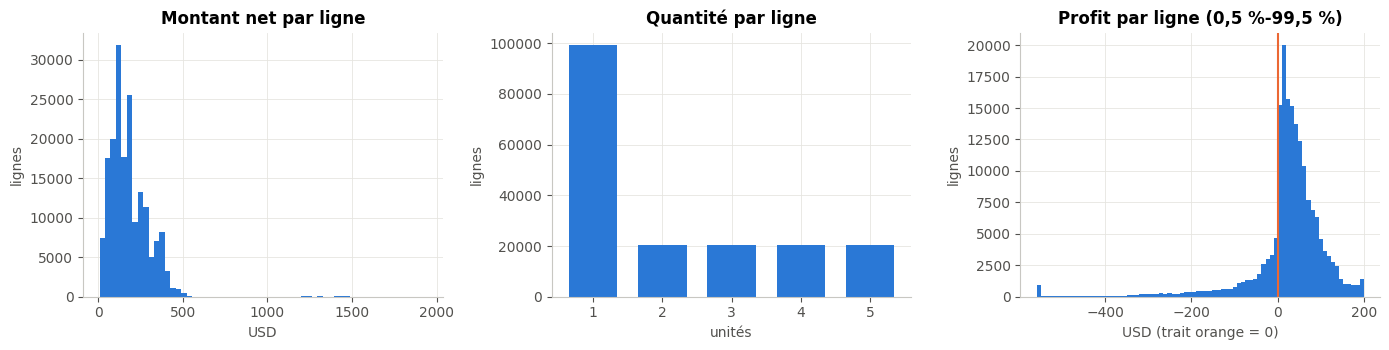

Part des lignes à profit négatif : 0.187
       montant_net   quantite  taux_remise     profit  jours_reels
count    180519.00  180519.00    180519.00  180519.00    180519.00
mean        183.11       2.13         0.10      21.97         3.50
std         120.04       1.45         0.07     104.43         1.62
min           7.49       1.00         0.00   -4274.98         0.00
25%         104.38       1.00         0.04       7.00         2.00
50%         163.99       1.00         0.10      31.52         3.00
75%         247.40       3.00         0.16      64.80         5.00
max        1939.99       5.00         0.25     911.80         6.00


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(df["montant_net"], bins=60, color=BLEU)
axes[0].set(title="Montant net par ligne", xlabel="USD", ylabel="lignes")
df["quantite"].value_counts().sort_index().plot.bar(ax=axes[1], color=BLEU, width=0.7, rot=0)
axes[1].set(title="Quantité par ligne", xlabel="unités", ylabel="lignes")
# On coupe les 0,5 % extrêmes de chaque côté pour lire la forme (les extrêmes restent dans describe()).
bas, haut = df["profit"].quantile([0.005, 0.995])
axes[2].hist(df["profit"].clip(bas, haut), bins=80, color=BLEU)
axes[2].axvline(0, color=ORANGE, lw=1.5)
axes[2].set(title="Profit par ligne (0,5 %-99,5 %)", xlabel="USD (trait orange = 0)", ylabel="lignes")
plt.tight_layout(); plt.show()

print("Part des lignes à profit négatif :", round((df["profit"] < 0).mean(), 3))
print(df[["montant_net", "quantite", "taux_remise", "profit", "jours_reels"]].describe().round(2))

In [11]:
# Délai réel par mode d'expédition (hors annulations) : répartition en %
exp = df[df["est_annulee"] == 0]
(pd.crosstab(exp["mode_expedition"], exp["jours_reels"], normalize="index") * 100).round(1)

jours_reels,0,1,2,3,4,5,6
mode_expedition,,,,,,,
First Class,0.0,0.0,100.0,0.0,0.0,0.0,0.0
Same Day,52.1,47.9,0.0,0.0,0.0,0.0,0.0
Second Class,0.0,0.0,20.2,20.0,20.0,20.0,19.8
Standard Class,0.0,0.0,20.2,20.1,19.9,19.6,20.2


> **Constat - distributions**
> - Les montants sont asymétriques (quelques produits chers), le profit est négatif sur environ 19 % des lignes : à suivre dans Power BI.
> - **Délais réels** : `First Class` (1 jour prévu) est livré systématiquement en 2 jours ; en `Second` et `Standard Class`, le délai réel est réparti **de façon quasi uniforme entre 2 et 6 jours**. Cette régularité suggère des données **simulées**, ce qui a une conséquence directe sur le modèle de risque (section 5).

## 5. Taux de retard (commandes expédiées)

Taux de retard global (expédiées) : 57.3%


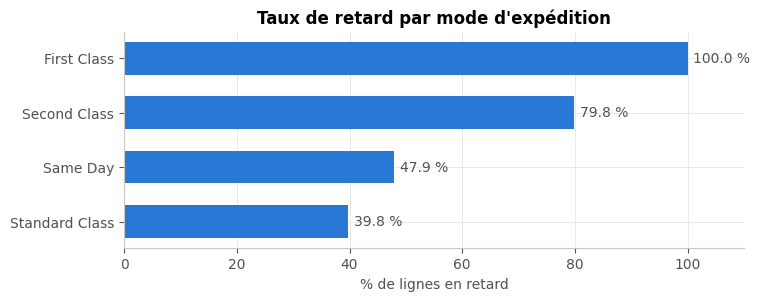

,taux_retard,lignes
mode_expedition,,
Standard Class,0.397691,103153
Same Day,0.479285,9293
Second Class,0.798290,33806
First Class,1.000000,26513


In [12]:
def taux_retard(col):
    return exp.groupby(col)["est_en_retard"].agg(taux_retard="mean", lignes="size").sort_values("taux_retard")

print(f"Taux de retard global (expédiées) : {exp['est_en_retard'].mean():.1%}")
t_mode = taux_retard("mode_expedition")
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(t_mode.index, t_mode["taux_retard"] * 100, color=BLEU, height=0.6)
for y, v in enumerate(t_mode["taux_retard"] * 100):
    ax.text(v + 1, y, f"{v:.1f} %", va="center", color=GRIS)
ax.set(title="Taux de retard par mode d'expédition", xlabel="% de lignes en retard", xlim=(0, 110))
plt.show()
t_mode

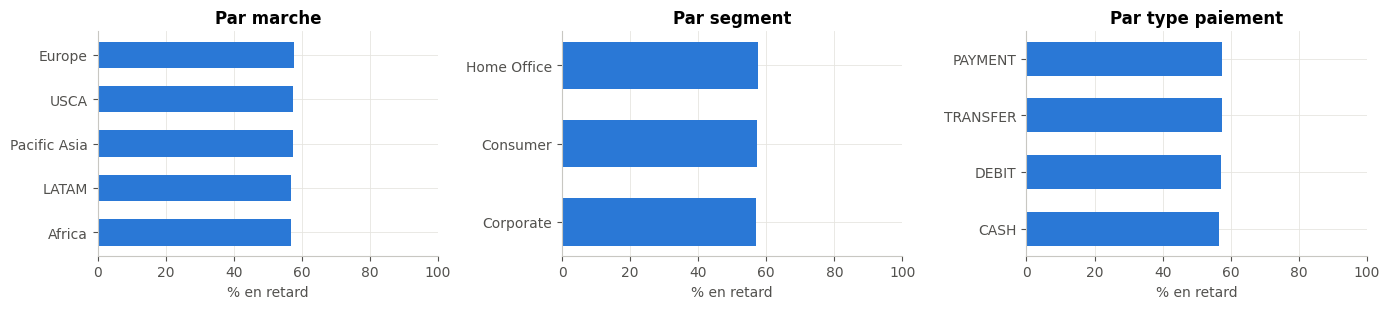

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharex=True)
for ax, col in zip(axes, ["marche", "segment", "type_paiement"]):
    t = taux_retard(col)
    ax.barh(t.index, t["taux_retard"] * 100, color=BLEU, height=0.6)
    ax.set(title=f"Par {col.replace('_', ' ')}", xlabel="% en retard", xlim=(0, 100))
plt.tight_layout(); plt.show()

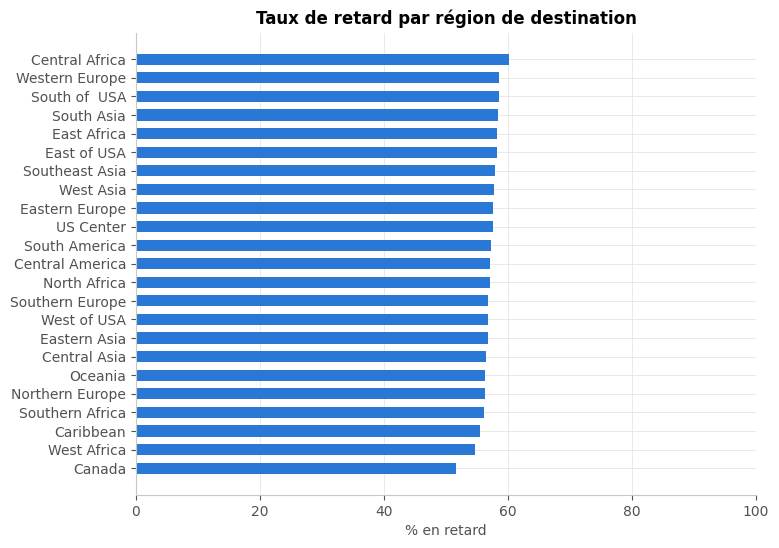

Écart entre la région la plus et la moins en retard : 8.5 points


In [14]:
t_reg = taux_retard("region")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(t_reg.index, t_reg["taux_retard"] * 100, color=BLEU, height=0.6)
ax.set(title="Taux de retard par région de destination", xlabel="% en retard", xlim=(0, 100))
plt.show()
print("Écart entre la région la plus et la moins en retard :",
      round((t_reg["taux_retard"].max() - t_reg["taux_retard"].min()) * 100, 1), "points")

In [15]:
# Le retard dépend-il d'autre chose que du mode ? On regarde l'écart à l'intérieur de chaque mode.
croise = exp.pivot_table(index="mode_expedition", columns="marche", values="est_en_retard", aggfunc="mean")
display((croise * 100).round(1))

lignes = []
for col in ["marche", "region", "segment", "type_paiement", "categorie", "quantite"]:
    t = exp.groupby(["mode_expedition", col])["est_en_retard"].agg(["mean", "size"])
    t = t[t["size"] >= 200]   # on ignore les petits groupes, trop bruités
    ecart = t.groupby(level=0)["mean"].agg(lambda s: s.max() - s.min())
    lignes.append((ecart * 100).round(1).rename(col))
print("Écart max-min du taux de retard (points de %) à mode d'expédition fixé, groupes >= 200 lignes :")
pd.concat(lignes, axis=1)

marche,Africa,Europe,LATAM,Pacific Asia,USCA
mode_expedition,,,,,
First Class,100.0,100.0,100.0,100.0,100.0
Same Day,46.4,48.8,50.4,45.4,46.4
Second Class,80.1,80.2,79.1,80.4,79.6
Standard Class,39.9,39.8,39.5,40.0,39.8


Écart max-min du taux de retard (points de %) à mode d'expédition fixé, groupes >= 200 lignes :


,marche,region,segment,type_paiement,categorie,quantite
mode_expedition,,,,,,
First Class,0.0,0.0,0.0,0.0,0.0,0.0
Same Day,5.0,19.4,4.2,2.9,3.3,2.3
Second Class,1.3,6.7,1.8,1.9,5.6,1.5
Standard Class,0.5,14.4,1.4,1.3,7.2,0.8


In [16]:
# Ces écarts sont-ils réels ou dus au hasard ? Test du khi-deux d'indépendance, mode par mode.
# (First Class est exclu : 100 % de retard, aucune variation à expliquer.)
from scipy.stats import chi2_contingency

tests = {}
for col in ["marche", "region", "segment", "type_paiement", "categorie", "quantite"]:
    tests[col] = {
        mode: chi2_contingency(pd.crosstab(g[col], g["est_en_retard"]))[1]
        for mode, g in exp.groupby("mode_expedition") if g["est_en_retard"].nunique() == 2
    }
print("p-valeurs (H0 : le retard est indépendant de la variable, à mode fixé) :")
pd.DataFrame(tests).T.round(4)

p-valeurs (H0 : le retard est indépendant de la variable, à mode fixé) :


,Same Day,Second Class,Standard Class
marche,0.0067,0.1951,0.8539
region,0.0000,0.0000,0.0000
segment,0.0108,0.0079,0.0019
type_paiement,0.4357,0.0821,0.0846
categorie,0.2236,0.8480,0.9988
quantite,0.7720,0.5486,0.8089


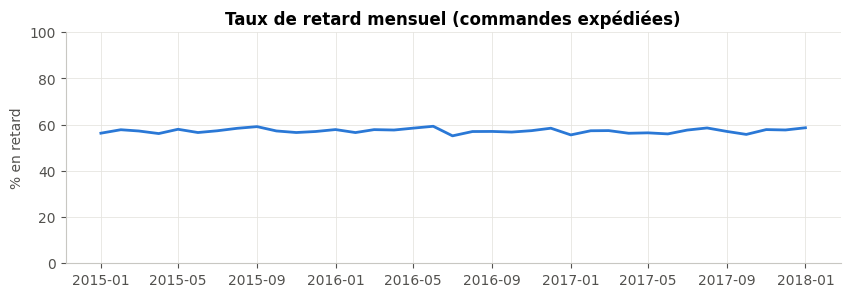

Min / max mensuel : 55.2 / 59.3


In [17]:
# Stabilité dans le temps (important pour le découpage temporel train/test)
mensuel = exp.set_index("date_commande").resample("MS")["est_en_retard"].mean() * 100
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(mensuel.index, mensuel.values, color=BLEU, lw=2)
ax.set(title="Taux de retard mensuel (commandes expédiées)", ylabel="% en retard", ylim=(0, 100))
plt.show()
print("Min / max mensuel :", round(mensuel.min(), 1), "/", round(mensuel.max(), 1))

> **Constat - taux de retard**
> - Le **mode d'expédition** est le facteur dominant : `First Class` est presque toujours en retard (délai prévu 1 jour, réel 2 jours), `Standard Class` l'est le moins.
> - Globalement, marché, segment et moyen de paiement font très peu varier le taux (quelques points autour de 57 %).
> - À mode fixé, le test du khi-deux montre que la **région** et le **segment** ont un effet **statistiquement significatif mais faible**. La catégorie, la quantité et le moyen de paiement n'ont pas d'effet détectable. Le marché n'en a que pour `Same Day`. C'est ce petit signal résiduel que le modèle de la phase 2 pourra essayer d'exploiter au-delà du mode.
> - Le taux est **stable dans le temps** : un découpage temporel train/test ne crée pas de dérive de la cible.
> - **Conséquence honnête pour la phase 2** : avec les seules informations connues à la commande, le signal disponible est **essentiellement le mode d'expédition**, plus un faible effet région/segment. Il faut s'attendre à un modèle **peu meilleur qu'une règle par mode**. On le mesurera au lieu de le supposer, et on le présentera comme un résultat, pas comme un échec (beaucoup de notebooks publics atteignent 97 % de précision précisément parce qu'ils utilisent les variables qui fuient).

## 6. Régularité de la série temporelle des ventes

Semaines : 162 | de 2014-12-29 à 2018-01-29


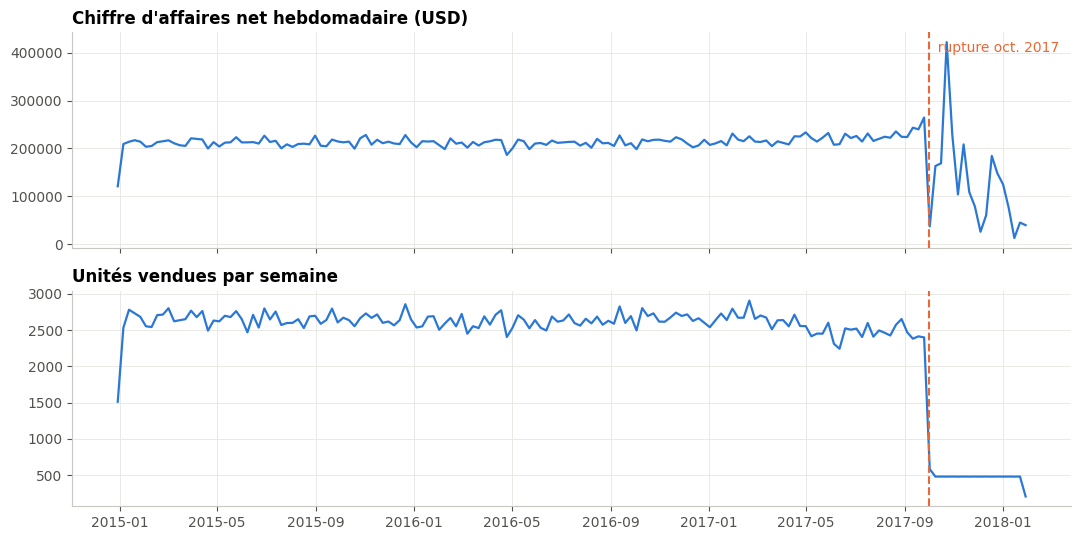

,ca,quantite,commandes
semaine,,,
2017-09-04,223886.0,2469,409
2017-09-11,243432.0,2381,405
2017-09-18,240035.0,2413,393
2017-09-25,264736.0,2398,399
2017-10-02,37073.0,582,469
2017-10-09,163329.0,479,479
2017-10-16,168901.0,480,480
2017-10-23,422430.0,479,479
2017-10-30,227864.0,480,480


In [18]:
df["semaine"] = df["date_commande"].dt.to_period("W-SUN").dt.start_time   # semaines du lundi au dimanche
hebdo = df.groupby("semaine").agg(ca=("montant_net", "sum"), quantite=("quantite", "sum"),
                                  commandes=("commande_id", "nunique"))
print("Semaines :", len(hebdo), "| de", hebdo.index.min().date(), "à", hebdo.index.max().date())

RUPTURE = pd.Timestamp("2017-10-01")
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, col, titre in [(axes[0], "ca", "Chiffre d'affaires net hebdomadaire (USD)"),
                       (axes[1], "quantite", "Unités vendues par semaine")]:
    ax.plot(hebdo.index, hebdo[col], color=BLEU, lw=1.6)
    ax.axvline(RUPTURE, color=ORANGE, lw=1.5, ls="--")
    ax.set_title(titre, loc="left")
axes[0].text(RUPTURE, hebdo["ca"].max() * 0.95, "  rupture oct. 2017", color=ORANGE)
plt.tight_layout(); plt.show()
hebdo.loc["2017-09-01":].round(0)

In [19]:
# Que se passe-t-il à partir d'octobre 2017 ?
avant, apres = df[df["date_commande"] < RUPTURE], df[df["date_commande"] >= RUPTURE]
cat_av, cat_ap = set(avant["categorie"]), set(apres["categorie"])
print(f"Catégories avant : {len(cat_av)} | après : {len(cat_ap)} | communes : {len(cat_av & cat_ap)}")
print("Nouvelles catégories après la rupture :", sorted(cat_ap - cat_av))
print("Lignes par commande avant / après :",
      round(avant.groupby('commande_id').size().mean(), 2), "/", round(apres.groupby('commande_id').size().mean(), 2))

# Les marchés couverts changent d'un trimestre à l'autre
pd.crosstab(df["date_commande"].dt.to_period("Q"), df["marche"])

Catégories avant : 32 | après : 31 | communes : 13
Nouvelles catégories après la rupture : ['Baby', 'Books', 'CDs', 'Cameras', "Children's Clothing", 'Computers', 'Consumer Electronics', 'Crafts', 'DVDs', 'Garden', 'Health and Beauty', "Men's Clothing", 'Music', 'Pet Supplies', 'Sporting Goods', 'Toys', 'Video Games', "Women's Clothing"]
Lignes par commande avant / après : 3.0 / 1.02


marche,Africa,Europe,LATAM,Pacific Asia,USCA
date_commande,,,,,
2015Q1,0,0,15413,0,0
2015Q2,0,5255,10362,0,0
2015Q3,0,15712,0,0,0
2015Q4,0,3947,0,11961,0
2016Q1,0,0,0,15421,0
2016Q2,0,0,0,159,15294
2016Q3,3071,983,0,1959,9786
2016Q4,7285,2889,0,5102,601
2017Q1,1258,563,12493,1038,118


Semaines stables : 143
Coefficient de variation hebdo du CA      : 0.055
Coefficient de variation hebdo des unités : 0.055


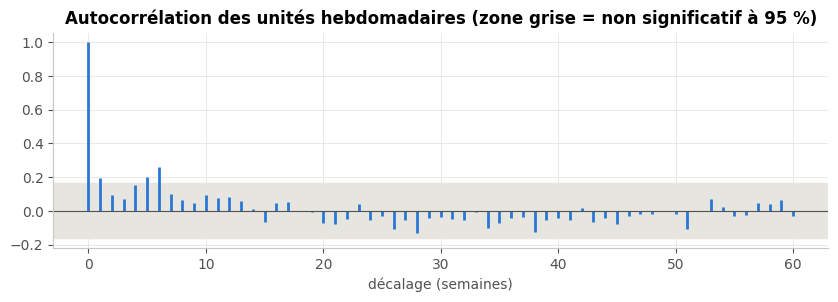

ACF lag 1 : 0.194 | lag 52 (saisonnalité annuelle) : -0.002


In [20]:
# Régularité sur la période stable (janv. 2015 -> sept. 2017)
stable = hebdo.loc[: RUPTURE - pd.Timedelta(days=1)].iloc[:-1]   # on retire la semaine à cheval sur la rupture
print("Semaines stables :", len(stable))
print("Coefficient de variation hebdo du CA      :", round(stable["ca"].std() / stable["ca"].mean(), 3))
print("Coefficient de variation hebdo des unités :", round(stable["quantite"].std() / stable["quantite"].mean(), 3))

auto = acf(stable["quantite"], nlags=60)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.vlines(range(len(auto)), 0, auto, color=BLEU, lw=2)
ax.axhline(0, color=GRIS, lw=0.8)
borne = 1.96 / np.sqrt(len(stable))
ax.axhspan(-borne, borne, color="#e6e5e0", zorder=0)
ax.set(title="Autocorrélation des unités hebdomadaires (zone grise = non significatif à 95 %)",
       xlabel="décalage (semaines)")
plt.show()
print("ACF lag 1 :", round(auto[1], 3), "| lag 52 (saisonnalité annuelle) :", round(auto[52], 3))

In [21]:
# Régularité par catégorie (période stable)
cat_sem = avant.groupby(["categorie", "semaine"])["quantite"].sum().unstack(0).fillna(0).iloc[:-1]
regularite = pd.DataFrame({
    "unites_moy_sem": cat_sem.mean(),
    "coef_variation": cat_sem.std() / cat_sem.mean(),
    "pct_semaines_nulles": (cat_sem == 0).mean() * 100,
    "part_ca_pct": avant.groupby("categorie")["montant_net"].sum() / avant["montant_net"].sum() * 100,
}).sort_values("part_ca_pct", ascending=False).round(2)
regularite["part_ca_cumulee"] = regularite["part_ca_pct"].cumsum().round(1)
regularite

,unites_moy_sem,coef_variation,pct_semaines_nulles,part_ca_pct,part_ca_cumulee
categorie,,,,,
Fishing,120.17,0.11,0.00,20.21,20.2
Cleats,511.99,0.09,0.00,12.92,33.1
Camping & Hiking,95.35,0.10,0.00,12.01,45.1
Cardio Equipment,260.78,0.12,0.00,10.77,55.9
Women's Apparel,436.80,0.10,0.00,9.18,65.1
Water Sports,107.72,0.11,0.00,9.08,74.2
Men's Footwear,154.47,0.10,0.00,8.43,82.6
Indoor/Outdoor Games,401.45,0.11,0.00,8.43,91.0
Shop By Sport,227.45,0.13,0.00,3.82,94.8


> **Constat - série temporelle (décision pour la phase 4)**
> - **Rupture nette en octobre 2017** : le catalogue change presque entièrement (nouvelles catégories : livres, jeux vidéo, jardin...), chaque commande ne contient plus qu'une ligne, et le volume s'effondre puis devient erratique. Les 4 derniers mois ne sont **pas comparables** au passé et ne doivent pas servir à évaluer une prévision.
> - **Les marchés tournent d'un trimestre à l'autre** (par ex. uniquement LATAM au T1 2015, uniquement Pacific Asia au T1 2016) : une agrégation **par région ou marché n'est pas viable**.
> - Sur la période stable (janvier 2015 -> septembre 2017), la demande totale est **très régulière** (coefficient de variation d'environ 5 %) et **sans saisonnalité annuelle** (autocorrélation au décalage 52 proche de 0).
> - Par catégorie, **9 catégories concentrent environ 95 % du CA** avec des séries régulières et sans semaine nulle ; les autres sont petites et intermittentes.
> - **Proposition pour la phase 4** : prévision hebdomadaire **par catégorie** sur les 9 catégories principales (les autres regroupées en « Autres »), entraînée et évaluée sur la période stable uniquement. Faute de saisonnalité, la baseline naïve (saisonnière ou moyenne mobile) sera difficile à battre : c'est un résultat attendu qu'on documentera honnêtement. La prévision des 12 semaines sera explicitement présentée comme un exercice méthodologique, la période post-rupture n'étant pas prévisible avec l'historique.

## 7. Synthèse et décisions

| Constat | Décision |
|---|---|
| Grain = ligne de commande, aucun doublon | `fait_commandes` au grain ligne (180 519 lignes) |
| 6 colonnes copiées, 3 vides/constantes, code postal de commande vide à 86 % | supprimées dans `src/etl/transform.py` |
| Prénom, nom, rue en clair | supprimés (avec e-mail et mot de passe) |
| Cible = `jours_reels > jours_prevus`, annulations forcées à 0 | délai réel, statut de livraison, date d'expédition, **statut de commande** exclus du modèle ; annulations exclues de l'apprentissage |
| Délai prévu entièrement déterminé par le mode | `dim_expedition` (4 lignes) porte `jours_prevus` |
| Retard ~ fonction du mode seul, stable dans le temps | découpage temporel sans risque de dérive ; attentes de performance modestes, mesurées en phase 2 |
| Rupture oct. 2017, marchés tournants, pas de saisonnalité | prévision par catégorie sur la période stable (phase 4) |